# Analisis Statistika Deskriptif Pipeline ETL (CSV, JSON, Parquet)
**Kelompok 1 – 3TIF – Statistika dan Probabilitas**

Notebook ini mengikuti urutan Lembar Perkuliahan Pertemuan 4:
**A. Pengorganisasian data → B. Penyajian data → C. Statistika deskriptif**.
Setiap sel diberi nomor tabel/gambar laporan yang dihasilkannya. Analisis hanya memakai **Pandas**
(grafik digambar dengan Matplotlib, yang juga dipakai oleh `DataFrame.plot`).

## 0. Persiapan

In [1]:
import os, math
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

os.makedirs("tabel", exist_ok=True)
os.makedirs("gambar", exist_ok=True)

URUTAN_FORMAT = ["CSV", "JSON", "Parquet"]
WARNA = {"CSV": "#2a78d6", "JSON": "#eb6834", "Parquet": "#1baf7a"}   # aman untuk buta warna
VARIABEL = {"total_waktu_detik": "Total waktu eksekusi (detik)",
            "memori_puncak_mb": "Memori puncak (MB)"}
TAHAP = ["waktu_baca_detik", "waktu_transformasi_detik", "waktu_tulis_detik"]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8986", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def angka_id(v, desimal=2, buang_nol=True):
    """Format angka Indonesia: titik ribuan, koma desimal."""
    teks = f"{v:,.{desimal}f}"
    if buang_nol and "." in teks:
        teks = teks.rstrip("0").rstrip(".")
    return teks.replace(",", "X").replace(".", ",").replace("X", ".")

koma = FuncFormatter(lambda v, _: angka_id(v, 3))

def simpan(fig, nama):
    fig.savefig(f"gambar/{nama}.png")
    plt.show()

## A. Pengorganisasian Data
### A.1 Import data (Bab 4.1)
Data dibaca dari file Excel tanpa kop tabel, seperti pada materi. Di Colab, file diunggah bila belum ada.

In [2]:
NAMA_BERKAS = "3TIF_01_PipelineETL.xlsx"
if not os.path.exists(NAMA_BERKAS):
    try:
        from google.colab import files          # hanya berjalan di Colab
        print("Unggah berkas", NAMA_BERKAS)
        NAMA_BERKAS = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Taruh {NAMA_BERKAS} di folder yang sama dengan notebook ini.")

dataraw = pd.read_excel(NAMA_BERKAS)
dataraw["timestamp"] = pd.to_datetime(dataraw["timestamp"])
dataraw["format_file"] = pd.Categorical(dataraw["format_file"], URUTAN_FORMAT, ordered=True)
dataraw = dataraw.sort_values("urutan_run").reset_index(drop=True)
print(dataraw.shape)
dataraw.head()

(150, 10)


,urutan_run,timestamp,format_file,jumlah_baris,waktu_baca_detik,waktu_transformasi_detik,waktu_tulis_detik,total_waktu_detik,memori_puncak_mb,status_run
0,1,2026-10-11 15:28:13,JSON,1000000,3.904701,0.232738,2.304401,6.441841,1761.265625,ok
1,2,2026-10-11 15:28:15,Parquet,1000000,0.097287,0.296063,0.427412,0.820762,348.687500,ok
2,3,2026-10-11 15:28:16,Parquet,1000000,0.103207,0.277842,0.416157,0.797207,358.578125,ok
3,4,2026-10-11 15:28:18,Parquet,1000000,0.090629,0.263849,0.389457,0.743934,347.261719,ok
4,5,2026-10-11 15:28:25,JSON,1000000,3.748049,0.231730,2.675060,6.654838,1761.246094,ok


### A.2 Pemeriksaan struktur dan kualitas data (Bab 4.1)

In [3]:
print("Kolom                 :", list(dataraw.columns))
print("\nTipe data:"); print(dataraw.dtypes.to_string())
print("\nNilai kosong per kolom:"); print(dataraw.isna().sum().to_string())
print("\nJumlah run per format:"); print(dataraw["format_file"].value_counts(sort=False).to_string())
print("\nStatus run:"); print(dataraw["status_run"].value_counts().to_string())
print("\nurutan_run unik dan berurutan 1..150 :",
      dataraw["urutan_run"].is_unique and dataraw["urutan_run"].tolist() == list(range(1, len(dataraw) + 1)))
print("timestamp tidak mundur               :", dataraw["timestamp"].is_monotonic_increasing)
print("Rentang waktu                        :", dataraw["timestamp"].min(), "sampai", dataraw["timestamp"].max())
print("Semua nilai ukur positif             :", bool((dataraw[list(VARIABEL) + TAHAP] > 0).all().all()))
print("total = baca + transformasi + tulis  :",
      bool(((dataraw[TAHAP].sum(axis=1) - dataraw["total_waktu_detik"]).abs() < 1e-6).all()))

# Cek pengacakan: format run sebelumnya vs format run sekarang
dataraw["format_sebelumnya"] = dataraw["format_file"].shift(1)
print("\nTabel silang format sebelumnya vs sekarang (cek pengacakan):")
print(pd.crosstab(dataraw["format_sebelumnya"], dataraw["format_file"]).to_string())

Kolom                 : ['urutan_run', 'timestamp', 'format_file', 'jumlah_baris', 'waktu_baca_detik', 'waktu_transformasi_detik', 'waktu_tulis_detik', 'total_waktu_detik', 'memori_puncak_mb', 'status_run']

Tipe data:
urutan_run                           int64
timestamp                   datetime64[us]
format_file                       category
jumlah_baris                         int64
waktu_baca_detik                   float64
waktu_transformasi_detik           float64
waktu_tulis_detik                  float64
total_waktu_detik                  float64
memori_puncak_mb                   float64
status_run                             str

Nilai kosong per kolom:
urutan_run                  0
timestamp                   0
format_file                 0
jumlah_baris                0
waktu_baca_detik            0
waktu_transformasi_detik    0
waktu_tulis_detik           0
total_waktu_detik           0
memori_puncak_mb            0
status_run                  0

Jumlah run per format:
fo

### A.3 Tabel 4.2 – Batas calon outlier 1,5 × IQR per variabel per format

In [4]:
def batas_iqr(x):
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

ok = dataraw[dataraw["status_run"] == "ok"].copy()
baris = []
for v in VARIABEL:
    ok[f"outlier_{v}"] = False
    for f in URUTAN_FORMAT:
        m = ok["format_file"] == f
        lo, hi = batas_iqr(ok.loc[m, v])
        flag = m & ((ok[v] < lo) | (ok[v] > hi))
        ok.loc[flag, f"outlier_{v}"] = True
        baris.append({"variabel": v, "format": f, "batas_bawah": lo, "batas_atas": hi,
                      "n_outlier": int(flag.sum()),
                      "nilai_outlier": ", ".join(angka_id(x, 3) for x in sorted(ok.loc[flag, v])),
                      "run_ke": ", ".join(str(r) for r in ok.loc[flag, "urutan_run"])})
pencilan = pd.DataFrame(baris)
pencilan.to_csv("tabel/batas_outlier.csv", index=False)
pencilan[["variabel", "format", "batas_bawah", "batas_atas", "n_outlier", "run_ke"]].round(3)

,variabel,format,batas_bawah,batas_atas,n_outlier,run_ke
0,total_waktu_detik,CSV,3.420,4.440,4,"33, 61, 120, 150"
1,total_waktu_detik,JSON,5.444,6.785,6,"6, 40, 49, 59, 60, 123"
2,total_waktu_detik,Parquet,0.582,0.870,4,"7, 35, 117, 118"
3,memori_puncak_mb,CSV,299.472,300.714,9,"8, 18, 27, 61, 65, 88, 120, 138, 142"
4,memori_puncak_mb,JSON,1761.034,1761.589,7,"15, 40, 41, 60, 80, 89, 136"
5,memori_puncak_mb,Parquet,334.243,372.426,0,


### A.4 Tabel 4.1 – Frekuensi run per format (crosstab seperti materi)

In [5]:
tabel41 = pd.crosstab(index=ok["format_file"], columns=ok["status_run"], margins=True, margins_name="Total")
for v, nama in [("total_waktu_detik", "Calon outlier waktu"), ("memori_puncak_mb", "Calon outlier memori")]:
    hit = ok.groupby("format_file", observed=True)[f"outlier_{v}"].sum()
    tabel41[nama] = list(hit) + [hit.sum()]
tabel41.to_csv("tabel/tabel_4_1_frekuensi_run.csv")
tabel41

status_run,ok,Total,Calon outlier waktu,Calon outlier memori
format_file,,,,
CSV,50,50,4,9
JSON,50,50,6,7
Parquet,50,50,4,0
Total,150,150,14,16


### A.5 Tabel distribusi frekuensi (Tabel 4.3–4.5 dan 4.7–4.9)
Banyak kelas memakai aturan Sturges, *k* = 1 + 3,322 log *n* = 7 untuk *n* = 50.
Kelas reguler dibentuk dari data **di dalam** batas 1,5 × IQR; calon outlier dimasukkan ke **kelas terbuka**
(di bawah batas bawah / di atas batas atas). Tanpa kelas terbuka, satu nilai ekstrem (misalnya 15 detik) akan
membuat hampir semua data jatuh ke kelas pertama sehingga tabel tidak informatif.

In [6]:
def tabel_frekuensi(seri):
    n = seri.count()
    k = math.ceil(1 + 3.322 * math.log10(n))
    lo, hi = batas_iqr(seri)
    normal = seri[(seri >= lo) & (seri <= hi)]
    lebar = (normal.max() - normal.min()) / k
    batas = [normal.min() + i * lebar for i in range(k + 1)]
    batas[-1] = normal.max() + 1e-9
    kelas = pd.cut(normal, bins=batas, right=False, include_lowest=True)
    tabel = pd.crosstab(index=kelas, columns="Frekuensi", dropna=False)   # kelas kosong tetap tampil
    d = 3 if lebar < 1 else 2                       # banyak desimal label kelas
    tabel.index = [f"{angka_id(a, d, False)} – < {angka_id(b, d, False)}" for a, b in zip(batas[:-1], batas[1:])]
    tabel["Titik tengah"] = [angka_id((a + b) / 2, d + 1, False) for a, b in zip(batas[:-1], batas[1:])]
    bawah, atas = int((seri < lo).sum()), int((seri > hi).sum())
    if bawah:
        tabel = pd.concat([pd.DataFrame({"Frekuensi": [bawah], "Titik tengah": ["–"]},
                                        index=[f"< {angka_id(lo, d, False)} (outlier)"]), tabel])
    if atas:
        tabel = pd.concat([tabel, pd.DataFrame({"Frekuensi": [atas], "Titik tengah": ["–"]},
                                               index=[f"> {angka_id(hi, d, False)} (outlier)"])])
    tabel.index.name = "Kelas"
    tabel["Frekuensi relatif (%)"] = tabel["Frekuensi"] / n * 100
    tabel["Frekuensi kumulatif"] = tabel["Frekuensi"].cumsum()
    info = {"k": k, "lebar": lebar, "batas": batas, "bawah": bawah, "atas": atas, "lo": lo, "hi": hi}
    return tabel[["Titik tengah", "Frekuensi", "Frekuensi relatif (%)", "Frekuensi kumulatif"]], info

FREK = {}
for v, label in VARIABEL.items():
    for f in URUTAN_FORMAT:
        t, info = tabel_frekuensi(ok.loc[ok["format_file"] == f, v])
        FREK[(v, f)] = (t, info)
        t.to_csv(f"tabel/frekuensi_{v}_{f}.csv")
        print(f"--- {label} | {f}  (k = {info['k']}, lebar kelas = {angka_id(info['lebar'], 4)})")
        print(t.round(1).to_string(), "\n")

--- Total waktu eksekusi (detik) | CSV  (k = 7, lebar kelas = 0,1077)
                  Titik tengah  Frekuensi  Frekuensi relatif (%)  Frekuensi kumulatif
Kelas                                                                                
< 3,420 (outlier)            –          1                    2.0                    1
3,635 – < 3,743         3,6891         10                   20.0                   11
3,743 – < 3,851         3,7968          4                    8.0                   15
3,851 – < 3,958         3,9045         16                   32.0                   31
3,958 – < 4,066         4,0122          8                   16.0                   39
4,066 – < 4,174         4,1199          3                    6.0                   42
4,174 – < 4,281         4,2276          3                    6.0                   45
4,281 – < 4,389         4,3353          2                    4.0                   47
> 4,440 (outlier)            –          3                    6.0      

--- Total waktu eksekusi (detik) | Parquet  (k = 7, lebar kelas = 0,0222)
                  Titik tengah  Frekuensi  Frekuensi relatif (%)  Frekuensi kumulatif
Kelas                                                                                
0,666 – < 0,688         0,6767         11                   22.0                   11
0,688 – < 0,710         0,6989         10                   20.0                   21
0,710 – < 0,732         0,7210          7                   14.0                   28
0,732 – < 0,754         0,7432          9                   18.0                   37
0,754 – < 0,776         0,7653          3                    6.0                   40
0,776 – < 0,799         0,7875          3                    6.0                   43
0,799 – < 0,821         0,8097          3                    6.0                   46
> 0,870 (outlier)            –          4                    8.0                   50 

--- Memori puncak (MB) | CSV  (k = 7, lebar kelas = 0,1133)
    

## B. Penyajian Data
### B.1 Gambar 4.1 dan 4.2 – Histogram (grafik batang), poligon frekuensi (grafik garis), dan boxplot
Tabel frekuensi disajikan sebagai histogram (grafik batang) dan poligon frekuensi (grafik garis yang
menghubungkan titik tengah kelas), seperti `datafrq.plot(kind="bar")` dan `datafrq.plot()` pada materi.
Setiap format memakai sumbu-x sendiri karena skalanya berbeda jauh. Outlier yang jatuh di luar sumbu
ditulis nilainya di dalam panel boxplot.

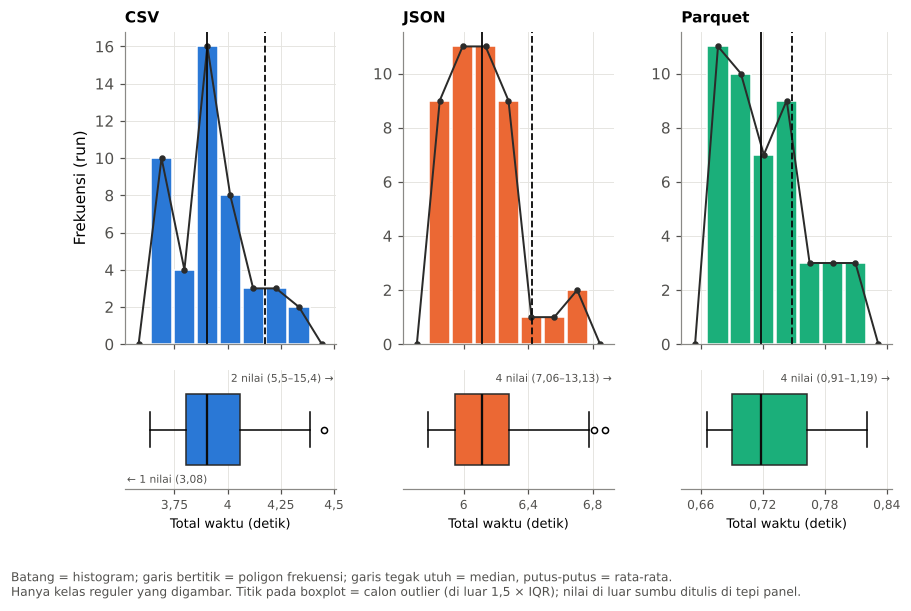

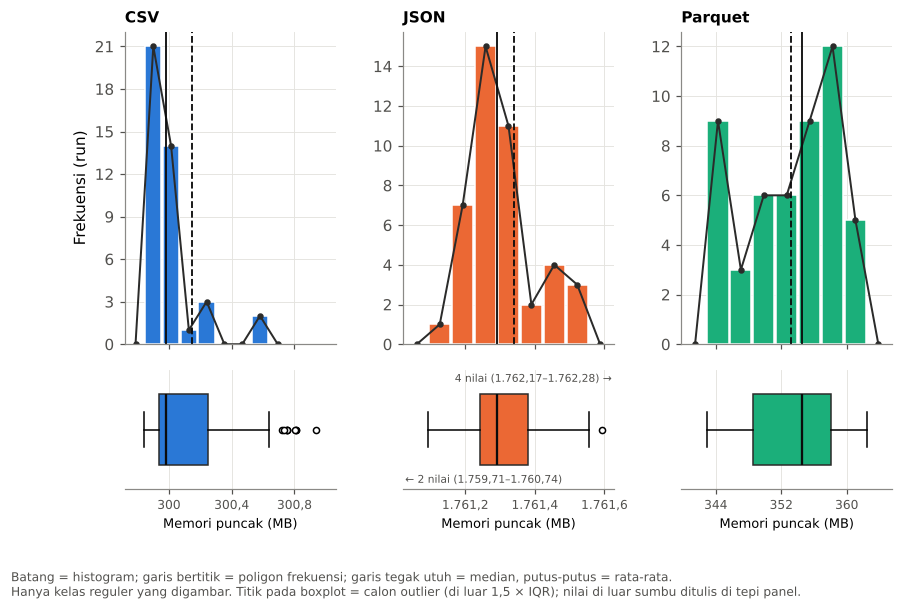

In [7]:
def gambar_sebaran(var, label, nama):
    fig = plt.figure(figsize=(9, 5.4))
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 0.38], hspace=0.12, wspace=0.32)
    for i, f in enumerate(URUTAN_FORMAT):
        dt = ok.loc[ok["format_file"] == f, var]
        t, info = FREK[(var, f)]
        b = info["batas"]; mid = [(x + y) / 2 for x, y in zip(b[:-1], b[1:])]
        reg = t[t["Titik tengah"] != "–"]["Frekuensi"].to_list()
        ax = fig.add_subplot(grid[0, i])
        ax.bar(mid, reg, width=info["lebar"] * 0.92, color=WARNA[f], edgecolor="white", linewidth=1)
        L = info["lebar"]                                   # poligon frekuensi: titik tengah kelas,
        ax.plot([mid[0] - L] + mid + [mid[-1] + L], [0] + reg + [0],   # ditutup ke nol di kedua ujung
                color="#2b2b2a", lw=1.3, marker="o", ms=3.2)
        ax.axvline(dt.median(), color="#0b0b0b", lw=1.2)
        if b[0] <= dt.mean() <= b[-1]:
            ax.axvline(dt.mean(), color="#0b0b0b", lw=1.2, ls="--")
        ax.set_title(f, fontsize=10, loc="left", fontweight="bold")
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(axis="x", labelbottom=False)
        if i == 0:
            ax.set_ylabel("Frekuensi (run)")
        rentang = b[-1] - b[0]
        lo_ax = min(dt.min(), b[0]) if dt.min() >= b[0] - 0.5 * rentang else b[0]
        hi_ax = max(dt.max(), b[-1]) if dt.max() <= b[-1] + 0.5 * rentang else b[-1]
        pad = max((hi_ax - lo_ax) * 0.06, info["lebar"] * 1.1)
        lo_ax, hi_ax = lo_ax - pad, hi_ax + pad
        ax.set_xlim(lo_ax, hi_ax)
        axb = fig.add_subplot(grid[1, i], sharex=ax)
        bp = axb.boxplot(dt, orientation="horizontal", widths=0.6, patch_artist=True,
                         medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                         flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "white"})
        bp["boxes"][0].set_facecolor(WARNA[f]); bp["boxes"][0].set_edgecolor("#2b2b2a")
        def ringkas(nilai):
            if len(nilai) == 1:
                return f"1 nilai ({angka_id(nilai[0])})"
            return f"{len(nilai)} nilai ({angka_id(nilai[0])}–{angka_id(nilai[-1])})"
        luar_kiri = sorted(dt[dt < lo_ax]); luar_kanan = sorted(dt[dt > hi_ax])
        if luar_kiri:
            axb.text(0.01, 0.03, "← " + ringkas(luar_kiri), transform=axb.transAxes,
                     ha="left", va="bottom", fontsize=7, color="#52514e")
        if luar_kanan:
            axb.text(0.99, 0.97, ringkas(luar_kanan) + " →", transform=axb.transAxes,
                     ha="right", va="top", fontsize=7, color="#52514e")
        axb.set_yticks([]); axb.grid(axis="y", visible=False); axb.spines["left"].set_visible(False)
        axb.xaxis.set_major_formatter(koma); axb.xaxis.set_major_locator(MaxNLocator(4))
        axb.tick_params(axis="x", labelsize=8); axb.set_xlabel(label, fontsize=8.5)
    fig.text(0.01, -0.07, "Batang = histogram; garis bertitik = poligon frekuensi; garis tegak utuh = median, putus-putus = rata-rata.\n"
             "Hanya kelas reguler yang digambar. Titik pada boxplot = calon outlier (di luar 1,5 × IQR); "
             "nilai di luar sumbu ditulis di tepi panel.", fontsize=8, color="#52514e")
    simpan(fig, nama)

gambar_sebaran("total_waktu_detik", "Total waktu (detik)", "gambar_4_1_sebaran_waktu")
gambar_sebaran("memori_puncak_mb", "Memori puncak (MB)", "gambar_4_2_sebaran_memori")

## C. Statistika Deskriptif
### C.1 Tabel 4.6 dan 4.10 – Statistik deskriptif per format
Baris `describe()` sampai `kurtosis` sama persis dengan kode pada materi; IQR, CV, dan batas outlier ditambahkan.
`mode()` tidak bermakna karena hampir semua nilai berbeda, sehingga modus dilaporkan sebagai **kelas modus**.

In [8]:
def statistik_deskriptif(dt):
    stats = dt.describe()
    stats["Standard Error"] = dt.sem()
    stats["Median"] = dt.median()
    stats["Mode"] = dt.mode().iloc[0]
    stats["variance"] = dt.var()
    stats["range"] = dt.max() - dt.min()
    stats["skewness"] = dt.skew()
    stats["kurtosis"] = dt.kurtosis()            # excess kurtosis (normal = 0)
    stats["IQR"] = stats["75%"] - stats["25%"]
    stats["CV (%)"] = stats["std"] / stats["mean"] * 100
    stats["Batas bawah outlier"] = stats["25%"] - 1.5 * stats["IQR"]
    stats["Batas atas outlier"] = stats["75%"] + 1.5 * stats["IQR"]
    stats["Jumlah outlier"] = ((dt < stats["Batas bawah outlier"]) | (dt > stats["Batas atas outlier"])).sum()
    stats["Jumlah nilai unik"] = dt.nunique()
    return stats

DESK = {}
for v, label in VARIABEL.items():
    kolom = {}
    for f in URUTAN_FORMAT:
        st = statistik_deskriptif(ok.loc[ok["format_file"] == f, v])
        t, _ = FREK[(v, f)]
        reg = t[t["Titik tengah"] != "–"]
        st["Kelas modus"] = reg["Frekuensi"].idxmax()
        st["Frekuensi kelas modus"] = reg["Frekuensi"].max()
        kolom[f] = st
    DESK[v] = pd.DataFrame(kolom)
    DESK[v].to_csv(f"tabel/deskriptif_{v}.csv")
    print(f"=== {label}")
    print(DESK[v].to_string(), "\n")

=== Total waktu eksekusi (detik)
                                   CSV             JSON          Parquet
count                             50.0             50.0             50.0
mean                           4.17669         6.421701         0.748059
std                           1.651038         1.218349         0.099644
min                           3.080573         5.780248         0.665605
25%                           3.802597         5.947081         0.690389
50%                           3.902022         6.111126         0.718365
75%                           4.057583         6.282149         0.762345
max                          15.404928         13.12627         1.190157
Standard Error                0.233492         0.172301         0.014092
Median                        3.902022         6.111126         0.718365
Mode                          3.080573         5.780248         0.665605
variance                      2.725926         1.484374         0.009929
range             

### C.2 Tabel 4.11 – Sensitivitas terhadap outlier
Calon outlier **tidak dibuang** dari analisis utama. Untuk melihat seberapa besar pengaruhnya, ukuran utama
dihitung ulang tanpa calon outlier dan dibandingkan dengan data penuh.

In [9]:
baris = []
for v, label in VARIABEL.items():
    for f in URUTAN_FORMAT:
        g = ok[ok["format_file"] == f]
        for nama, dt in [("Penuh", g[v]), ("Tanpa outlier", g.loc[~g[f"outlier_{v}"], v])]:
            baris.append({"Variabel": label, "Format": f, "Data": nama, "n": dt.count(),
                          "Rata-rata": dt.mean(), "Median": dt.median(), "SD": dt.std(),
                          "CV (%)": dt.std() / dt.mean() * 100,
                          "Skewness": dt.skew(), "Kurtosis": dt.kurtosis()})
sensitivitas = pd.DataFrame(baris)
sensitivitas.to_csv("tabel/sensitivitas_outlier.csv", index=False)
sensitivitas.round(4)

,Variabel,Format,Data,n,Rata-rata,Median,SD,CV (%),Skewness,Kurtosis
0,Total waktu eksekusi (detik),CSV,Penuh,50,4.1767,3.9020,1.6510,39.5298,6.6831,46.1662
1,Total waktu eksekusi (detik),CSV,Tanpa outlier,46,3.9217,3.8984,0.1813,4.6241,0.6718,0.1346
2,Total waktu eksekusi (detik),JSON,Penuh,50,6.4217,6.1111,1.2183,18.9724,4.5027,21.7341
3,Total waktu eksekusi (detik),JSON,Tanpa outlier,44,6.1073,6.0882,0.2214,3.6243,1.0758,1.3683
4,Total waktu eksekusi (detik),Parquet,Penuh,50,0.7481,0.7184,0.0996,13.3203,2.7653,8.7912
5,Total waktu eksekusi (detik),Parquet,Tanpa outlier,46,0.7229,0.7139,0.0428,5.9201,0.7273,-0.3400
6,Memori puncak (MB),CSV,Penuh,50,300.1473,299.9805,0.3405,0.1134,1.2438,-0.1445
7,Memori puncak (MB),CSV,Tanpa outlier,41,300.0070,299.9531,0.1704,0.0568,2.6116,7.2076
8,Memori puncak (MB),JSON,Penuh,50,1761.3405,1761.2910,0.3695,0.0210,-0.7724,8.8114
9,Memori puncak (MB),JSON,Tanpa outlier,43,1761.3048,1761.2852,0.1017,0.0058,0.7661,0.5417


### C.3 Tabel 4.12 dan Gambar 4.3 – Waktu per tahap ETL (diagram lingkaran)

             waktu_baca_detik  waktu_transformasi_detik  waktu_tulis_detik  jumlah_median_tahap
format_file                                                                                    
CSV                    1.0064                    0.2235             2.6546               3.8845
JSON                   3.5996                    0.2268             2.2582               6.0846
Parquet                0.0918                    0.2405             0.3827               0.7150


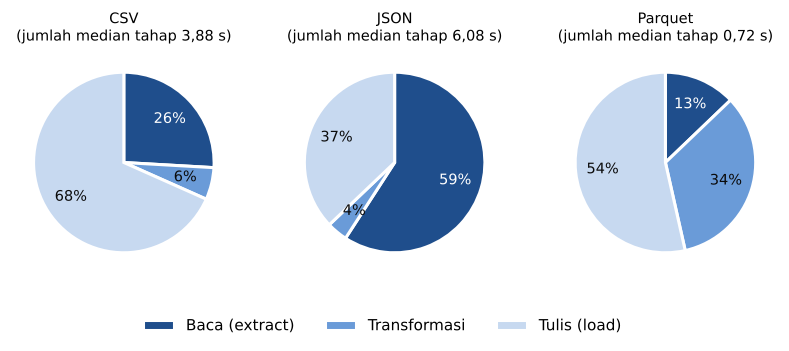

In [10]:
tahap = ok.groupby("format_file", observed=True)[TAHAP].median()
tahap["jumlah_median_tahap"] = tahap.sum(axis=1)
tahap.to_csv("tabel/median_waktu_per_tahap.csv")
print(tahap.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
for ax, f in zip(axes, URUTAN_FORMAT):
    nilai = tahap.loc[f, TAHAP]
    _, _, teks = ax.pie(nilai, colors=["#1f4e8c", "#6a9bd8", "#c7d9f0"], startangle=90, counterclock=False,
                        autopct=lambda p: f"{p:.0f}%", pctdistance=0.7,
                        wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 9.5})
    for t, w in zip(teks, ["white", "#0b0b0b", "#0b0b0b"]):
        t.set_color(w)
    ax.set_title(f"{f}\n(jumlah median tahap {angka_id(nilai.sum())} s)", fontsize=9.5)
fig.legend(["Baca (extract)", "Transformasi", "Tulis (load)"], loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.subplots_adjust(bottom=0.14)
simpan(fig, "gambar_4_3_komposisi_tahap")

### C.4 Gambar 4.4 dan Tabel 4.13 – Perbandingan median antarformat (grafik batang)

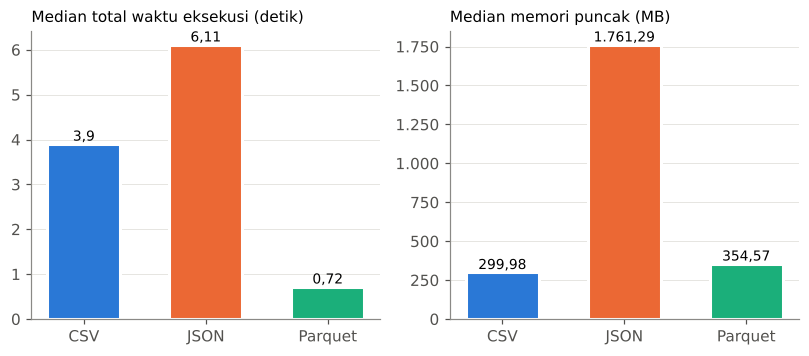

,Median waktu (detik),Rasio waktu thd Parquet,Median memori (MB),Rasio memori thd Parquet
CSV,3.902,5.432,299.980,0.846
JSON,6.111,8.507,1761.291,4.967
Parquet,0.718,1.000,354.574,1.000


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (v, label) in zip(axes, VARIABEL.items()):
    med = DESK[v].loc["Median", URUTAN_FORMAT].astype(float)
    batang = ax.bar(URUTAN_FORMAT, med, color=[WARNA[f] for f in URUTAN_FORMAT], width=0.6,
                    edgecolor="white", linewidth=2)
    for b, val in zip(batang, med):
        ax.text(b.get_x() + b.get_width() / 2, val, angka_id(val), ha="center", va="bottom", fontsize=9)
    ax.set_title("Median " + label[0].lower() + label[1:], fontsize=10, loc="left")
    ax.yaxis.set_major_formatter(koma); ax.grid(axis="x", visible=False)
simpan(fig, "gambar_4_4_median_per_format")

med_w = DESK["total_waktu_detik"].loc["Median"].astype(float)
med_m = DESK["memori_puncak_mb"].loc["Median"].astype(float)
rasio = pd.DataFrame({"Median waktu (detik)": med_w, "Rasio waktu thd Parquet": med_w / med_w["Parquet"],
                      "Median memori (MB)": med_m, "Rasio memori thd Parquet": med_m / med_m["Parquet"]})
rasio.to_csv("tabel/rasio_antar_format.csv")
rasio.round(3)

### C.5 Gambar 4.5 – Grafik garis menurut urutan run (stabilitas selama sesi)
Titik = satu run, garis tebal = median bergerak 10 run. Untuk melihat apakah nilai bergeser selama sesi,
median 25 run pertama dibandingkan dengan median 25 run terakhir setiap format.

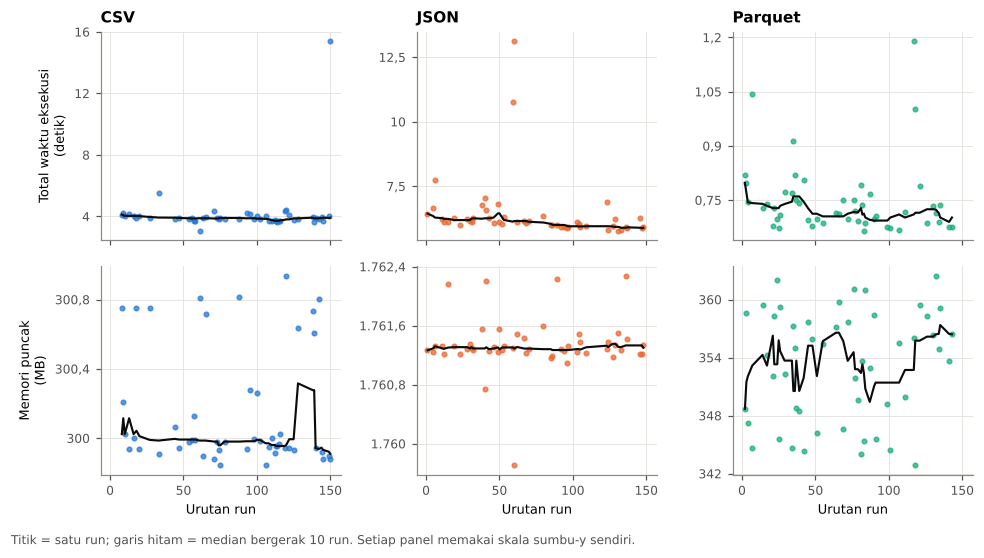

,Variabel,Format,Median 25 run pertama,Median 25 run terakhir,Perubahan (%)
0,Total waktu eksekusi (detik),CSV,3.9154,3.8557,-1.5244
1,Total waktu eksekusi (detik),JSON,6.2507,5.9433,-4.9173
2,Total waktu eksekusi (detik),Parquet,0.7397,0.7048,-4.7215
3,Memori puncak (MB),CSV,299.9922,299.9570,-0.0117
4,Memori puncak (MB),JSON,1761.2969,1761.2852,-0.0007
5,Memori puncak (MB),Parquet,354.2773,354.8711,0.1676


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(9, 4.9), sharex=True)
for r, (v, label) in enumerate(VARIABEL.items()):
    for c, f in enumerate(URUTAN_FORMAT):
        ax = axes[r, c]
        g = ok[ok["format_file"] == f].sort_values("urutan_run")
        ax.plot(g["urutan_run"], g[v], "o", ms=3, color=WARNA[f], alpha=0.75)
        ax.plot(g["urutan_run"], g[v].rolling(10, center=True, min_periods=5).median(),
                color="#0b0b0b", lw=1.4)
        ax.yaxis.set_major_formatter(koma); ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.tick_params(labelsize=8)
        if r == 0: ax.set_title(f, fontsize=10, loc="left", fontweight="bold")
        if c == 0: ax.set_ylabel(label.replace(" (", "\n("), fontsize=8.5)
        if r == 1: ax.set_xlabel("Urutan run", fontsize=8.5)
fig.tight_layout()
fig.text(0.01, -0.02, "Titik = satu run; garis hitam = median bergerak 10 run. Setiap panel memakai skala sumbu-y sendiri.",
         fontsize=8, color="#52514e")
simpan(fig, "gambar_4_5_urutan_run")

baris = []
for v, label in VARIABEL.items():
    for f in URUTAN_FORMAT:
        x = ok[ok["format_file"] == f].sort_values("urutan_run")[v]
        awal, akhir = x.head(25).median(), x.tail(25).median()
        baris.append({"Variabel": label, "Format": f, "Median 25 run pertama": awal,
                      "Median 25 run terakhir": akhir, "Perubahan (%)": (akhir - awal) / awal * 100})
tren = pd.DataFrame(baris)
tren.to_csv("tabel/median_awal_akhir_sesi.csv", index=False)
tren.round(4)

### Ringkasan angka kunci (dipakai untuk menulis Bab 4)

In [13]:
for v, label in VARIABEL.items():
    d = DESK[v].T
    print(f"{label}:")
    for f in URUTAN_FORMAT:
        print(f"  {f:8s} median {angka_id(float(d.loc[f,'Median']),4):>10s} | rata-rata {angka_id(float(d.loc[f,'mean']),4):>10s} "
              f"| CV {angka_id(float(d.loc[f,'CV (%)']),2):>6s}% | outlier {int(d.loc[f,'Jumlah outlier'])}")
print("\nSemua tabel tersimpan di folder tabel/, semua gambar di folder gambar/.")

Total waktu eksekusi (detik):
  CSV      median      3,902 | rata-rata     4,1767 | CV  39,53% | outlier 4
  JSON     median     6,1111 | rata-rata     6,4217 | CV  18,97% | outlier 6
  Parquet  median     0,7184 | rata-rata     0,7481 | CV  13,32% | outlier 4
Memori puncak (MB):
  CSV      median   299,9805 | rata-rata   300,1473 | CV   0,11% | outlier 9
  JSON     median  1.761,291 | rata-rata 1.761,3405 | CV   0,02% | outlier 7
  Parquet  median   354,5742 | rata-rata   353,1902 | CV   1,63% | outlier 0

Semua tabel tersimpan di folder tabel/, semua gambar di folder gambar/.
